# 5k Performance Analysis

This project examines how age and gender are associated with 5k performance across community races hosted through RunSignup.

## Research Question

**How are age and gender associated with 5k performance, and how do these patterns differ when performance is measured using raw finish time versus age- and gender-adjusted performance?**


### Database Connection and Setup

The analysis uses a SQLite database populated by cleaned RunSignup race results. The relational database separates race, event, and participant-result data into linked tables.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf


conn = sqlite3.connect("../data/processed/5k_performance.db")

### Dataset Overview
The final dataset contains results from multiple editions of six recurring community 5k races. Because race coverage varies substantially by year and event, the data is treated as a collection of race performances rather than as a longitudinal sample. 

The database contains three tables:
- `races`: race metadata
- `events`: individual 5k editions associated with each race
- `results`: participant performance records

In [2]:
overview = """
    SELECT
        races.race_name,
        COUNT(DISTINCT events.event_id) AS num_events,
        COUNT(results.result_id) AS num_results
    FROM races
    JOIN events
        ON races.race_id = events.race_id
    JOIN results
        ON events.event_id = results.event_id
    GROUP BY
        races.race_id,
        races.race_name
    ORDER BY num_results DESC;
"""

race_overview = pd.read_sql_query(overview, conn)
race_overview

,race_name,num_events,num_results
0,10th Annual Bobcats Turkey Trot 5K,4,1696
1,#RUNMARANA Mother's Day 5k and Kid’s Free FUN Run,8,1545
2,"10th Annual Holly Springs Half Marathon, 10k & 5k",5,1232
3,11th Annual New Beginnings for Tomorrow 5K Run...,6,263
4,11th Annual Oy Vey 5K,6,198
5,11th Annual Equal Access Birmingham Heart + So...,1,139


The dataset contains 5,073 performance records across 30 editions of six recurring 5k dates. Event representation is not even, as the three largest race series account for approximately 88% of total observations. Therefore, race and event context should be considered when interpreting pooled performance patterns.

In [3]:
sample_query = """
    SELECT
        COUNT(*) AS total_records,
        COUNT(chip_time_seconds) AS records_with_finish_time,
        COUNT(age) AS records_with_age,
        COUNT(
            CASE
                WHEN chip_time_seconds IS NOT NULL
                AND age IS NOT NULL
                THEN 1
            END
        ) AS modeling_records
    FROM results;
"""

sample_overview = pd.read_sql_query(sample_query, conn)
sample_overview

,total_records,records_with_finish_time,records_with_age,modeling_records
0,5073,4910,5034,4875


Not every result included a recorded chip time or valid age. Subsequent analyses use all available observations relevant to each measure rather than imputing missing performance or demographic values. The regression sample contains 4,875 records with both valid age and finish time. 

### Exploratory Data Analysis

In [4]:
finish_time_query = """
    SELECT
        chip_time_seconds / 60.0 AS finish_time_minutes
    FROM results
    WHERE chip_time_seconds IS NOT NULL;
"""

finish_times = pd.read_sql_query(finish_time_query, conn)

finish_times["finish_time_minutes"].describe()

count    4910.000000
mean       36.605428
std        10.892673
min        15.829333
25%        28.693833
50%        34.744167
75%        42.741833
max       139.420167
Name: finish_time_minutes, dtype: float64

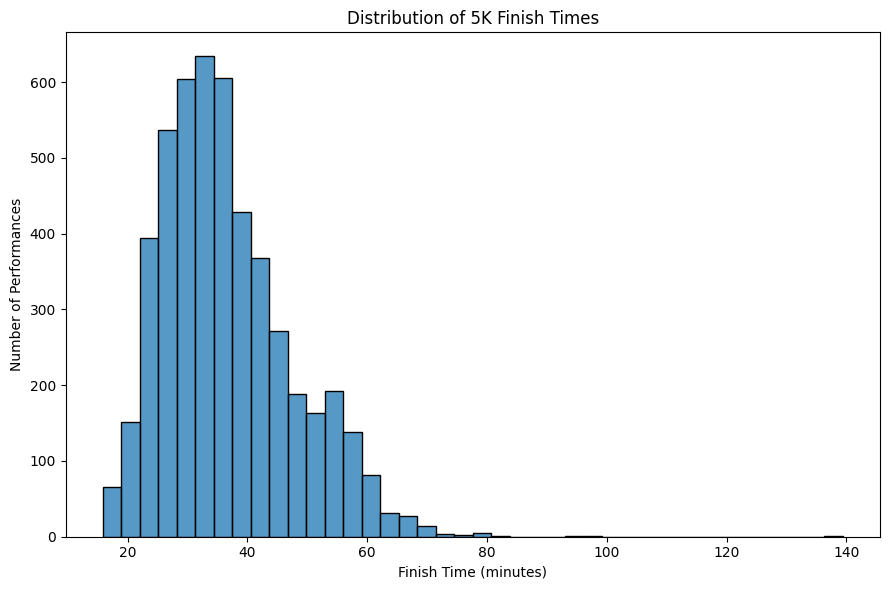

In [5]:
plt.figure(figsize=(9, 6))

sns.histplot(data=finish_times, x="finish_time_minutes", bins=40)

plt.xlabel("Finish Time (minutes)")
plt.ylabel("Number of Performances")
plt.title("Distribution of 5K Finish Times")
plt.tight_layout()
plt.show()

Finish times are right-skewed with most performances concentrated below approximately 50 minutes and a smaller number of substantially slower results. Because the distribution includes a long upper tail, median finish times are used along with means in subsequent descriptive comparisons.

Extreme finish times were kept when they were internally consistent with the source results rather than removed solely for being outliers.

In [6]:
age_query = """
    SELECT age
    FROM results
    WHERE age IS NOT NULL;
"""

ages = pd.read_sql_query(age_query, conn)

ages["age"].describe()

count    5034.000000
mean       33.858363
std        16.215235
min         1.000000
25%        20.000000
50%        35.000000
75%        45.000000
max        86.000000
Name: age, dtype: float64

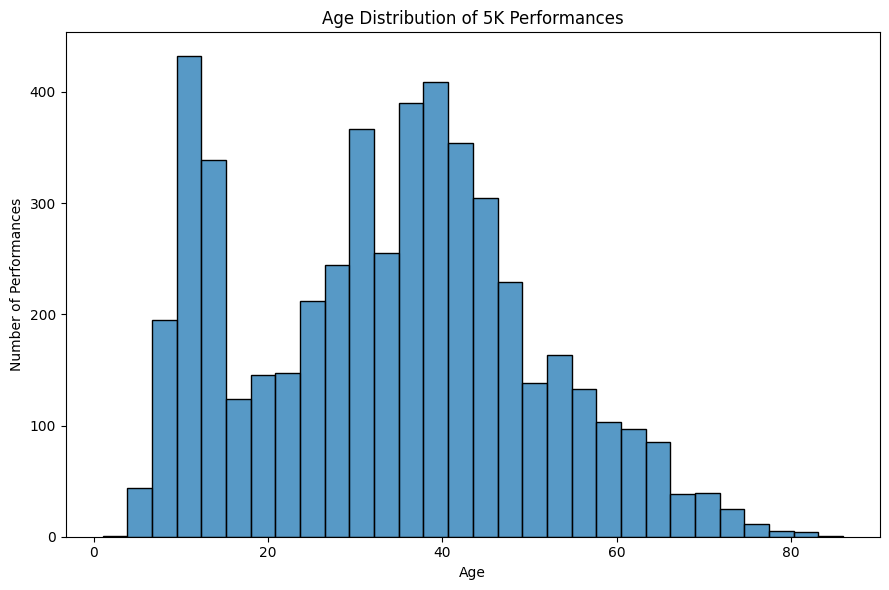

In [7]:
plt.figure(figsize=(9, 6))

sns.histplot(data=ages, x="age", bins=30)

plt.xlabel("Age")
plt.ylabel("Number of Performances")
plt.title("Age Distribution of 5K Performances")
plt.tight_layout()
plt.show()

The age distribution is broad and multimodal, reflecting participation by both younger runners and adults. This structure suggests that the relationship between performance and age may not be best represented by a simple linear trend.

Because the dataset contains race performances rather than identified unique individuals, repeated participation across race editions cannot be determined.

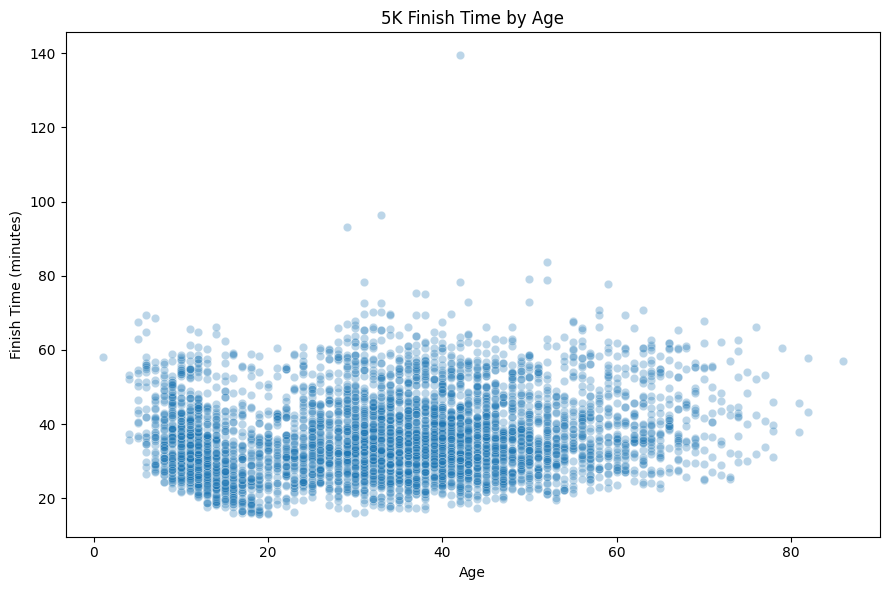

In [8]:
age_time_query = """
    SELECT
        age, 
        chip_time_seconds / 60.0 AS finish_time_minutes
    FROM results
    WHERE age IS NOT NULL
        AND chip_time_seconds IS NOT NULL;
"""

age_time = pd.read_sql_query(age_time_query, conn)

plt.figure(figsize=(9, 6))

sns.scatterplot(data=age_time, x="age", y="finish_time_minutes", alpha=0.3)

plt.xlabel("Age")
plt.ylabel("Finish Time (minutes)")
plt.title("5K Finish Time by Age")
plt.tight_layout()
plt.show()

There appears to be a nonlinear relationship between age and raw finish time. Younger children tend to have slower times than teenagers and young adults, while the lower boundary of finish times generally rises again at older ages. At the same time, a considerable amount of variation exists within nearly every age. This pattern motivates the use of age groups for descriptive comparisons and a quadratic age term in the regression analysis.



### Age and Gender Performance Patterns

To examine differences in raw 5k performance, runners were grouped into age categories and compared by gender. Median finish time is emphasized because the finish time distribution is right-skewed.

In [9]:
performance_query = """ 
    SELECT
        age,
        gender,
        chip_time_seconds / 60.0 AS finish_time_minutes,
        age_percentage_numeric
    FROM results
    WHERE age IS NOT NULL;
"""

performance = pd.read_sql_query(performance_query, conn)

In [10]:
age_bins = [0, 10, 20, 30, 40, 50, 60, 70, float("inf")]
age_labels = ["Under 10", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70+"]

performance["age_group"] = pd.cut(performance["age"], bins=age_bins, labels=age_labels, right=False)

In [11]:
age_gender_summary = (performance.groupby(
    ["age_group", "gender"], observed=True).agg(
        n=("finish_time_minutes", "count"),
        mean_finish_time=("finish_time_minutes", "mean"),
        median_finish_time=("finish_time_minutes", "median"),
        mean_age_percentage=("age_percentage_numeric", "mean"),
        median_age_percentage=("age_percentage_numeric", "median"),
    ).reset_index())

age_gender_summary

,age_group,gender,n,mean_finish_time,median_finish_time,mean_age_percentage,median_age_percentage
0,Under 10,F,94,42.923699,41.925000,44.765591,43.90
1,Under 10,M,133,37.269504,35.471667,49.326667,49.50
2,10-19,F,418,35.698902,33.964000,47.059861,46.60
3,10-19,M,540,29.302034,27.065500,51.192168,51.60
4,20-29,F,421,37.889851,35.746667,40.617483,40.40
5,20-29,M,210,31.191981,29.162083,44.745972,44.40
6,30-39,F,865,39.263280,37.028333,40.005390,39.80
7,30-39,M,374,32.156700,30.345417,44.344503,43.05
8,40-49,F,642,39.426425,37.688917,41.695282,41.00
9,40-49,M,372,33.636646,32.047500,44.768684,43.75


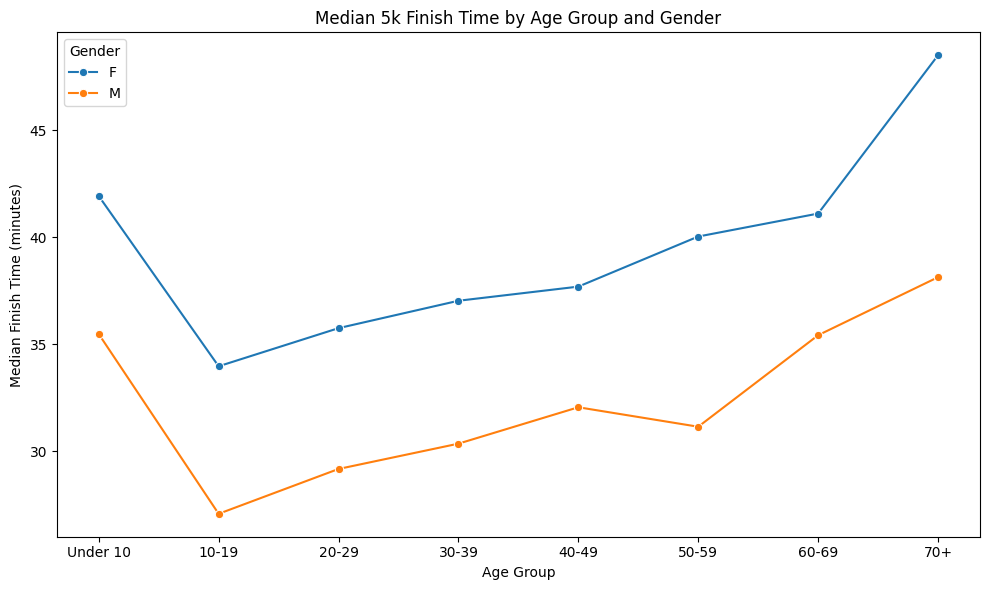

In [12]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=age_gender_summary,
    x="age_group",
    y="median_finish_time",
    hue="gender",
    marker="o"
)

plt.xlabel("Age Group")
plt.ylabel("Median Finish Time (minutes)")
plt.title("Median 5k Finish Time by Age Group and Gender")
plt.legend(title="Gender")
plt.tight_layout()
plt.savefig("../figures/median_finish_time_by_age_gender.png",
            dpi=300, bbox_inches="tight")

plt.show()



Raw finish times vary substantially across age groups. For both genders, median performances is fastest among teenagers, followed by slower median times across much of adulthood and into older age groups.

Male runners have lower median raw finish times than female runners within each age group in this sample. However, raw finish time does not account for expected physiological differences associated with age and gender. Therefore, the next section compares these patterns using age- and gender-adjusted performance. 

### Raw vs. Age-Adjusted Performance

Raw finish time measures absolute performance but does not account for expected performance differences associated with age and gender. To provide a standardized comparison, RunSignup reports an **Age Percentage**, commonly referred to as **age grading**. RunSignup calculates age-graded results using standards and age factors approved through World Masters Athletics (WMA) and USA Track & Field (USATF).

Age grading compares a runner's finish time with an age- and gender-specific standard for the same distance. Conceptually, the percentage represents the ratio of the benchmark performance to the runner's actual performance, so higher percentages indicate stronger performance relative to the standard. A score approaching 100% represents performance approaching the applicable world-best standard. 

In this analysis, age percentage is treated as an **alternative standardized
performance metric**, rather than as a measure of absolute speed. Comparing
raw finish time with age-adjusted performance allows us to examine how
conclusions about age and gender change depending on how 5K performance is
defined.

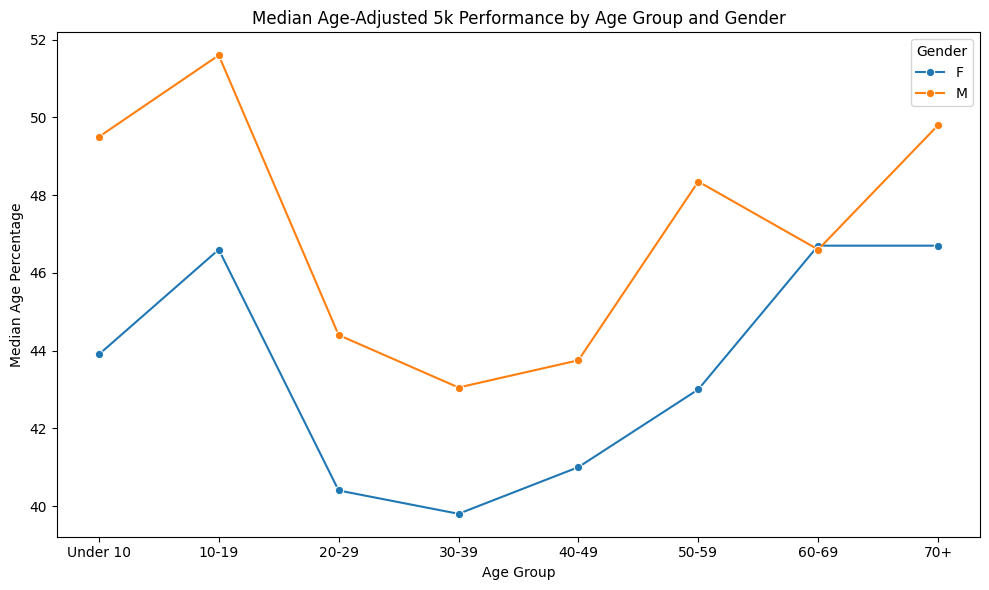

In [13]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=age_gender_summary,
    x="age_group",
    y="median_age_percentage",
    hue="gender",
    marker="o"
)

plt.xlabel("Age Group")
plt.ylabel("Median Age Percentage")
plt.title("Median Age-Adjusted 5k Performance by Age Group and Gender")
plt.legend(title="Gender")
plt.tight_layout()
plt.savefig("../figures/median_age_adjusted_by_age_gender.png",
            dpi=300, bbox_inches="tight")

plt.show()

Age-adjusted performance shows a significantly different pattern from raw finish time. While teenagers remain strong performers, several older age groups rank much more favorably after adjustment. In particular, the oldest runners perform strongly relative to age- and gender-specific standards despite having slower absolute finish times.

Gender differences also narrow for some age groups after adjustment. This illustrates that raw finish time and age-adjusted performance capture difference aspects of 5k performance: one measures absolute speed, while the other measures performance relative to demographic-specific benchmarks. 

In [14]:
rank_comparison = age_gender_summary[["age_group", "gender", "median_finish_time", "median_age_percentage"]].copy()

rank_comparison["raw_performance_rank"] = (
    rank_comparison.groupby("gender")["median_finish_time"].rank(
        method="min", ascending=True))

rank_comparison["adjusted_performance_rank"] = (
    rank_comparison.groupby("gender")["median_age_percentage"].rank(
        method="min", ascending=False))

rank_comparison.sort_values(["gender", "raw_performance_rank"])

,age_group,gender,median_finish_time,median_age_percentage,raw_performance_rank,adjusted_performance_rank
2,10-19,F,33.964000,46.60,1.0,3.0
4,20-29,F,35.746667,40.40,2.0,7.0
6,30-39,F,37.028333,39.80,3.0,8.0
8,40-49,F,37.688917,41.00,4.0,6.0
10,50-59,F,40.031417,43.00,5.0,5.0
12,60-69,F,41.105500,46.70,6.0,1.0
0,Under 10,F,41.925000,43.90,7.0,4.0
14,70+,F,48.508167,46.70,8.0,1.0
3,10-19,M,27.065500,51.60,1.0,1.0
5,20-29,M,29.162083,44.40,2.0,6.0


The ranking comparison reinforces the visual result. Several older groups move upward when performance is evaluated relative to age- and gender-specific standards, while some younger-adult groups move downward. Therefore, conclusions about which age groups perform most strongly depend considerably on whether performance is defined in absolute or age-adjusted terms.

These rankings are descriptive comparisons among broad age groups in this sample and should not be interpreted as rankings indicative of the general population.

### Regression Analysis

The descriptive analysis suggests that the relationship between age and raw 5k finish time is nonlinear and that performance also differs by gender. However, the dataset combines results from 30 separate race events, which may differ in course difficulty, weather, participant composition, and other event-specific conditions. 

Hence, a series of ordinary least squares (OLS) regression models is fitted with finish time in minutes as the outcome to estimate associations between age, gender, and raw finish time while progressively accounting for these features of the data. The models are developed incrementally:

1. A baseline linear model using age and gender.
2. A quadratic model allowing the relationship between age and finish time to be nonlinear.
3. A final model adding event fixed effects to account for systematic differences across the 30 race editions.

These models estimate associations within this sample and are not intended to establish causal effects of age or gender on running performance.

In [15]:
model_query = """ 
    SELECT
        result_id,
        event_id,
        age,
        gender,
        chip_time_seconds / 60.0 AS finish_time_minutes
    FROM results
    WHERE age IS NOT NULL
        AND chip_time_seconds IS NOT NULL;
"""

model_df = pd.read_sql_query(model_query, conn)
model_df.shape

(4875, 5)

The regression sample contains 4,875 performances with both a valid age and recorded finish time. Observations missing either variable are excluded rather than imputed.

#### Baseline Linear Model

In [16]:
baseline_model = smf.ols("finish_time_minutes ~ age + C(gender)", data=model_df).fit()

baseline_model.rsquared

np.float64(0.11948789267019333)

The baseline model assumes that the association between age and finish time is linear while accounting for gender. It explains approximately **11.9% of the observed variation in finish time.** However, the exploratory scatterplot showed that the age-performance relationship is curved rather than strictly linear. A linear age term alone provides an overly restrictive represeantion of the observed pattern.

#### Quadratic Linear Model

In [17]:
quadratic_model = smf.ols("finish_time_minutes ~ age + I(age ** 2) + C(gender)", data=model_df).fit()

quadratic_model.rsquared

np.float64(0.13002475306449446)

A quadratic age term is added to allow the estimated relationship between age and finish time to curve rather than force a constant change per year of age. The model's R-squared increases from **0.119 to 0.130**, providing modest evidence that the nonlinear specification better represents the observed age pattern.

However, race performances are also nested within individual events. Pooling all observations without accounting for event context treats performance from different race editions as directly comparable. As a result, the final model includes event fixed effects.

#### Final Model: Quadratic Age + Gender + Event Fixed Effects

In [18]:
model_df["age_centered"] = model_df["age"] - model_df["age"].mean()

model_df["age_centered_sq"] = model_df["age_centered"] ** 2

For the final specification, age is centered around the sample mean before constructing the quadratic term. Centering does not change the underlying shape of the fitted age curve, but makes the linear age coefficient easier to interpret and reduces dependence between the linear and squared age terms.

Event fixed effects are included using `C(event_id)`. This gives each race edition its own intercept, accounting for differences in average finish time across events. The model compares age and gender associations after controlloing for the particular event in which a performance was recorded.

In [19]:
event_model = smf.ols("finish_time_minutes ~ age_centered + age_centered_sq + C(gender) + C(event_id)", data=model_df).fit()

print(f"R^2: {event_model.rsquared:.3f}")
print(f"Adjusted R^2: {event_model.rsquared_adj:.3f}")


R^2: 0.237
Adjusted R^2: 0.232


Adding event fixed effects considerably increases explanatory power. The final model explains **~23.7% of the observed variation in finish time** (adjusted R^2 = **0.232**), compared to 13.0% for the quadratic age and gender model without event controls. This improvement indicates that race-event context accounts for meaningful variation in observed finish times. It also supports treating performances as nested within distinct race editions rather than as completely interchangeable observations.

#### Accounting for Within-Event Dependence

Performances from the same race edition may share conditions such as course, weather, timing procedures, or participant environment. As a result, errors among observations from the same event may not be independent. 

To account for this dependence, cluster-robust standard errors are calculated at the event level. The coefficient estimates belong to the event fixed-effects model, while their uncertainty is adjusted for correlation among performances within the same event. Because the dataset contains only 30 event clusters, inferential results should be interpreted cautiously.

In [20]:
clustered_model = event_model.get_robustcov_results(cov_type="cluster", groups=model_df["event_id"])

print(clustered_model.summary())

                             OLS Regression Results                            
Dep. Variable:     finish_time_minutes   R-squared:                       0.237
Model:                             OLS   Adj. R-squared:                  0.232
Method:                  Least Squares   F-statistic:                     998.4
Date:                 Sun, 27 Sep 2026   Prob (F-statistic):           9.26e-28
Time:                         17:39:53   Log-Likelihood:                -17890.
No. Observations:                 4875   AIC:                         3.584e+04
Df Residuals:                     4844   BIC:                         3.604e+04
Df Model:                           30                                         
Covariance Type:               cluster                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept         

/opt/homebrew/Caskroom/miniconda/base/envs/5k-analysis/lib/python3.10/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 30, but rank is 3
  res = self.wald_test(


In [21]:
mean_age = model_df["age"].mean()

centered_turning_point = (-event_model.params["age_centered"] / (2 * event_model.params["age_centered_sq"]))

age_turning_point = mean_age + centered_turning_point

print(f"Mean age: {mean_age:.1f}")
print(f"Estimated minimum of age curve: {age_turning_point:.1f}")

Mean age: 33.9
Estimated minimum of age curve: 26.7


#### Model Intepretation

The final model estimates a curved association between age and raw 5k finish time. The fitted age curve reaches its minimum near **age 26.7**, after which predicted finish time generally increases with age. This turning point describes the fitted relationship in this dataset rather than an exact biological age of peak running performance.

Conditional on age and race event, male performances are associated with **~5.5-minute lower finish times** than female performances in this sample.

The model should not be interpreted casually. It does not account for training history, fitness level, course characteristics within events (i.e. how hilly a course is), weather, injury, or other individual-level factors that may influence finish time. 

### Key Findings and Limitations


#### Key Findings

This analysis examined how age and gender are associated with 5k performance across 5,073 results from 30 editions of six community races.

Several patterns emerged:

- **Age and raw 5k performance have a nonlinear relationship.** Median finish times were fastest among teenagers in the descriptive age-group analysis, while the regression model estimated a minimum in the fitted age curve near age 26.7.

- **Gender differences were visible in raw finish times.** Male performances had lower median finish times within each age group in this sample. After controlling for age and race event, male performances were assocaited with approximately 5.5 minute lower finish times.

- **Age grading changes the interpretation of performance.** Older runners, particularly those in the oldest age groups, ranked more favorably when performance was measured relative to age- and gender-specific standards rather than by absolute finish time. Some younger-adult groups moved in the opposite direction. 

- **Race-event context matters.** Adding event fixed effects increased model R^2 from approximately 0.130 to 0.237, indicating that differences among race editions account for meaningful variation in observed finish times.

Together, these results show that conclusions about 5k performance depend on how performance is defined. Raw finish time captures absolute speed, while age grading provides a complementary view of performance relative to demographic-specific benchmarks.

#### Limitations

Several limitations should be considered when interpreting these results:

- The dataset is not a random or representative sample of all 5k runners. It contains participants from six selected RunSignup races, with the majority of observations coming from three larger race series.

- Race coverage is uneven across years, so the data should not be interpreted as a longitudinal sample or used to infer changes in running performance over time.

- Individual runners cannot be reliably identified across events. A runner who participated in multiple race editions may appear multiple times and this repeated-runner dependence cannot be modeled directly.

- Event fixed effects account for systematic differences in average finish times across race editions, but the dataset does not contain detailed information about factors such as weather, elevation, course difficulty, training history, or individual fitness.

- Cluster-robust standard errors account for potential dependence among performances within the same event, but inference should be interpreted cautiously because the analysis contains only 30 event clusters.

- Age grading is a benchmark-based metric constructed using age- and gender-specific standards. It provides a useful alternative perspective on performance but should not be interpreted as an objective measure of a runner's overall ability.

### Conclusion

Absolute and age-adjusted measures tell different but complementary stories about 5k performance. While raw finish times emphasize differences in absolute speed across age and gender groups, age grading significantly changes the relative standing of several groups. Accounting for race-event context further shows that performance cannot be understood solely from runner demographics.

Rather than identifying a single "best" measure of performance, this analysis demonstrates why the choice of metric and analytical context matters when comparing runners across a diverse recreational racing population.